# Cancelamento de reservas de hotel: análise exploratória

**Pergunta:** quais reservas têm mais chance de ser canceladas, no momento em que entram?

**Para quê:** decidir em quais reservas pedir depósito ou ligar para confirmar, e quantos cancelamentos esperar para calibrar o overbooking.

**Este notebook** decide quais variáveis entram no modelo e de que forma. O modelo e a avaliação ficam em `02_modelo.ipynb`.

## Resumo

*(preenchido ao final da análise)*

- Taxa de cancelamento: __.
- Variáveis excluídas por vazamento: __.
- Escopo do modelo: __.
- Variáveis que entram, e de que forma: __.

## Contexto e abordagem

**Contexto.** Dois hotéis em Portugal, um urbano (City Hotel, em Lisboa) e um resort (Resort Hotel, no Algarve), com chegadas de julho de 2015 a agosto de 2017. Cada linha é uma reserva. Uma reserva cancelada (ou um no-show) pode virar quarto vazio: a diária não entra e muitas vezes não dá tempo de revender o quarto. Fonte: Antonio, Almeida e Nunes (2019), *Hotel booking demand datasets*, Data in Brief.

**Abordagem.** Regressão logística: o resultado é sim ou não (cancelou ou veio), e o negócio precisa de uma probabilidade de cancelamento por reserva para decidir onde agir.

**Premissa que guia a análise.** O modelo será usado **no momento em que a reserva entra**. Então só pode usar o que o hotel sabe nessa hora. Uma variável que só existe, ou só tem aquele valor, depois do check-in ou do cancelamento é **vazamento**: deixa o modelo ótimo no papel e inútil na prática.

**Validação.** Pela mesma premissa, o modelo é avaliado em reservas futuras: treino com as chegadas de 2015 e 2016, teste com as de 2017.

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.append('..')   # o módulo de funções do projeto fica em analise/
from funcoes_logistica import (aplicar_estilo, resumo_colunas,
                               taxa_por_nivel, grafico_taxa_por_nivel, contar_casos)

aplicar_estilo()
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 80)

## 1. A base

In [2]:
hotel = pd.read_csv('../../dados/hotel_bookings.csv')
print('Linhas e colunas:', hotel.shape)
hotel.head()

Linhas e colunas: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
resumo_colunas(hotel)

,tipo,n_niveis,missing,pct_missing,mais_frequentes
hotel,str,2,0,0.000000,City Hotel (79.330) | Resort Hotel (40.060)
is_canceled,int64,2,0,0.000000,0 (75.166) | 1 (44.224)
lead_time,int64,479,0,0.000000,0 (6.345) | 1 (3.460) | 2 (2.069)
arrival_date_year,int64,3,0,0.000000,2016 (56.707) | 2017 (40.687) | 2015 (21.996)
arrival_date_month,str,12,0,0.000000,August (13.877) | July (12.661) | May (11.791)
arrival_date_week_number,int64,53,0,0.000000,33 (3.580) | 30 (3.087) | 32 (3.045)
arrival_date_day_of_month,int64,31,0,0.000000,17 (4.406) | 5 (4.317) | 15 (4.196)
stays_in_weekend_nights,int64,17,0,0.000000,0 (51.998) | 2 (33.308) | 1 (30.626)
stays_in_week_nights,int64,35,0,0.000000,2 (33.684) | 1 (30.310) | 3 (22.258)
adults,int64,14,0,0.000000,2 (89.680) | 1 (23.027) | 3 (6.202)


**Leitura.**

- **119.390 reservas e 32 colunas.** O `y` (`is_canceled`) já vem como 0/1: 44.224 canceladas (37,0%), contando os no-shows.
- **O tipo no Python nem sempre é o tipo da variável:**
  - `is_repeated_guest` é número, mas binária;
  - `agent` e `company` são decimais só porque têm missing: são códigos, ou seja, categóricas;
  - ano, semana e dia da chegada são números, mas são calendário.
- **Missing:** `company` (94,3%), `agent` (13,7%), `country` (488 reservas) e `children` (4 reservas).
- **Primeiros sinais para investigar:**
  - `reservation_status`: 43.017 Canceled + 1.207 No-Show = 44.224, exatamente as reservas canceladas. É o próprio `y` escrito de outro jeito: se entrasse no modelo, ele acertaria tudo no papel e não serviria para nada na prática. Sai (confirmar na seção de vazamento).
  - `deposit_type`: 88% das reservas são sem depósito (104.641), 12% Non Refund (14.587) e só 162 Refundable. A ação em discussão (pedir depósito ou ligar para confirmar) só faz sentido para quem ainda não deu garantia: candidato a definir o **escopo** do modelo, e não a entrar como variável. As 162 Refundable são poucas demais para estimar qualquer efeito.
  - `babies`: 0 em 99% das reservas (118.473). Uma variável quase constante separa pouco quem cancela de quem vem. Candidata a sair, ou a ser juntada com `children` ("tem criança ou bebê").
  - `distribution_channel`: 82% das reservas chegam por agências de viagem ou operadoras de turismo (TA/TO, *travel agents / tour operators*). O `market_segment` já separa esse grupo em agência online (Online TA) e agência ou operadora tradicional (Offline TA/TO), então o canal provavelmente repete o segmento com menos detalhe. Candidata a sair por redundância (confirmar com o V de Cramér entre os dois).

## 2. Dicionário de dados, primeira versão

O que cada variável é e o que esperamos dela **antes de olhar a relação com o cancelamento**. A coluna **Quando se sabe** aplica a premissa do momento da decisão:

- **na reserva:** o hotel tem a informação quando a reserva entra;
- **pode mudar até a chegada:** existe na reserva, mas a base guarda o valor do fim;
- **só no fim:** só existe depois do check-in ou do cancelamento (vazamento);
- **?:** não sabemos, e os dados vão mostrar.

| Variável | Descrição | Tipo | Quando se sabe | Pergunta a responder |
| :--- | :--- | :--- | :--- | :--- |
| **Hotel e antecedência** | | | | |
| `hotel` | City Hotel (Lisboa) ou Resort Hotel (Algarve) | categórica (2) | na reserva | O urbano cancela mais que o resort? |
| `lead_time` | Dias entre a reserva e a chegada | numérica | na reserva | Mais antecedência, mais chance de mudar de plano? A relação com o logito é linear? |
| **Data da chegada** | | | | |
| `arrival_date_year` | Ano da chegada | calendário (3) | na reserva | Não serve como variável: reserva futura sempre tem ano novo. Separa treino e teste. |
| `arrival_date_month` | Mês da chegada | categórica (12) | na reserva | Há sazonalidade? Dá para agrupar em temporadas? |
| `arrival_date_week_number` | Semana do ano da chegada | calendário (53) | na reserva | Acrescenta algo ao mês? |
| `arrival_date_day_of_month` | Dia do mês da chegada | calendário (31) | na reserva | Tem alguma lógica de negócio? |
| **Estadia e hóspedes** | | | | |
| `stays_in_weekend_nights` | Noites de sábado ou domingo | contagem | pode mudar até a chegada | Lazer (fim de semana) × trabalho (semana)? |
| `stays_in_week_nights` | Noites de segunda a sexta | contagem | pode mudar até a chegada | Vale somar com as noites de fim de semana? |
| `adults` | Adultos | contagem | na reserva | Reserva sem adulto é erro de cadastro? |
| `children` | Crianças | contagem | na reserva | Família cancela mais? |
| `babies` | Bebês | contagem | na reserva | Quase sempre zero: ajuda em algo? |
| `meal` | Regime: BB, HB, FB, SC, Undefined | categórica (5) | na reserva | Pela documentação, Undefined e SC são a mesma coisa (sem refeição). Os dados confirmam? |
| **Origem e canal** | | | | |
| `country` | País do hóspede | categórica (177) | ? | Pode ser preenchido só no check-in. Se for, é vazamento. |
| `market_segment` | Segmento: Online TA (agências online, como Booking.com), Offline TA/TO (agências tradicionais e operadoras, que costumam reservar blocos de quartos), Groups, Direct, Corporate... | categórica (8) | na reserva | Grupos e operadoras se comportam diferente? Algum nível tem poucas reservas? |
| `distribution_channel` | Canal: TA/TO (agências de viagem e operadoras de turismo), Direct, Corporate, GDS (sistemas de reserva usados por agências) | categórica (5) | na reserva | Repete o segmento? |
| `agent` | Código da agência | código (333) | na reserva | Centenas de códigos sem significado para o público. |
| `company` | Código da empresa que paga | código (352) | na reserva | 94% vazia: ajuda em algo? |
| `customer_type` | Transient, Transient-Party, Contract, Group | categórica (4) | na reserva | Cliente avulso cancela mais que contrato e grupo? |
| **Histórico do cliente** | | | | |
| `is_repeated_guest` | Já se hospedou antes | binária | na reserva | Quem volta cancela menos? |
| `previous_cancellations` | Reservas anteriores canceladas pelo cliente | contagem | na reserva | Quem já cancelou cancela de novo? |
| `previous_bookings_not_canceled` | Reservas anteriores que o cliente manteve | contagem | na reserva | Repete o `is_repeated_guest`? |
| **Quarto, pedidos e pagamento** | | | | |
| `reserved_room_type` | Tipo de quarto reservado (código anônimo) | categórica (10) | na reserva | O código não significa nada para o público. |
| `assigned_room_type` | Tipo de quarto entregue | categórica (12) | só no fim | Definido no check-in: quem cancelou nunca recebeu quarto. |
| `booking_changes` | Alterações até o check-in ou o cancelamento | contagem | só no fim | No momento da reserva, é sempre zero. |
| `deposit_type` | No Deposit, Non Refund (pago, sem reembolso), Refundable | categórica (3) | na reserva | Quem pagou sem reembolso cancela menos? A ação em discussão (pedir depósito) só vale para quem ainda não deu garantia. |
| `days_in_waiting_list` | Dias em lista de espera até a confirmação | numérica | na reserva | Esperar muito leva a desistir? |
| `adr` | Diária média | numérica | na reserva | Há diárias negativas ou zeradas? Diária alta, mais cancelamento? |
| `required_car_parking_spaces` | Vagas de garagem pedidas | contagem | ? | Pode ser pedida só na chegada. Se for, é vazamento. |
| `total_of_special_requests` | Pedidos especiais (cama de casal, andar alto...) | contagem | pode mudar até a chegada | Quem faz pedido pretende vir? |
| **Status da reserva** | | | | |
| `reservation_status` | Check-Out, Canceled, No-Show | categórica (3) | só no fim | É o próprio `y` escrito de outro jeito. |
| `reservation_status_date` | Data do último status | data | só no fim | Para quem cancelou, é a data do cancelamento. |
| **Variável resposta** | | | | |
| `is_canceled` | 1 = cancelada (inclui no-show), 0 = o hóspede veio | binária | | Qual a taxa de cancelamento? |

## 3. O cancelamento (o `y`)

**Perguntas:** quanto se cancela? O evento é raro? A taxa é estável no tempo?

A última importa por causa da validação: o modelo aprende com as chegadas de 2015 e 2016 e é testado nas de 2017. Se a taxa mudar entre os dois períodos, as probabilidades previstas para 2017 podem sair deslocadas.

Nesta seção a base é a inteira. O escopo do modelo é decidido na seção 5.

In [4]:
taxa_geral = hotel['is_canceled'].mean()

contagem = hotel['is_canceled'].value_counts().sort_index()
display(pd.DataFrame({'reservas': contagem, 'pct': contagem / contagem.sum()})
          .rename(index={0: 'veio (0)', 1: 'cancelou (1)'}))

# o status final só serve para descrever o y: Canceled e No-Show caem todos em y = 1
pd.crosstab(hotel['reservation_status'], hotel['is_canceled'], margins=True, margins_name='total')


,reservas,pct
is_canceled,,
veio (0),75166,0.629584
cancelou (1),44224,0.370416


is_canceled,0,1,total
reservation_status,,,
Canceled,0,43017,43017
Check-Out,75166,0,75166
No-Show,0,1207,1207
total,75166,44224,119390


In [5]:
taxa_por_nivel(hotel, 'hotel')

,n,pct_base,eventos,taxa,ic_inf,ic_sup,logito
hotel,,,,,,,
City Hotel,79330,0.664461,33102,0.417270,0.413842,0.420705,-0.333988
Resort Hotel,40060,0.335539,11122,0.277634,0.273270,0.282040,-0.956203


**Leitura.**

- **44.224 das 119.390 reservas foram canceladas (37,0%).** Pelo status final, 43.017 avisaram o cancelamento e 1.207 não apareceram (no-show). As duas situações ficam juntas no `y`: para o hotel, as duas viram quarto vazio. O no-show é o caso mais caro, porque não deixa tempo para revender o quarto.
- **Não é um evento raro.** Com 37% de cancelamento, não é preciso balancear a base nem usar técnica de evento raro.
- **A taxa geral é a referência.** Sem modelo, a melhor estimativa para qualquer reserva é 37%. O modelo só tem valor se separar reservas bem mais arriscadas de reservas bem mais seguras do que isso.
- **O hotel urbano cancela mais:** 41,7% (IC 95% de 41,4% a 42,1%) contra 27,8% no resort, e tem dois terços das reservas. A diferença é o primeiro corte de negócio, e o modelo precisa considerá-la.

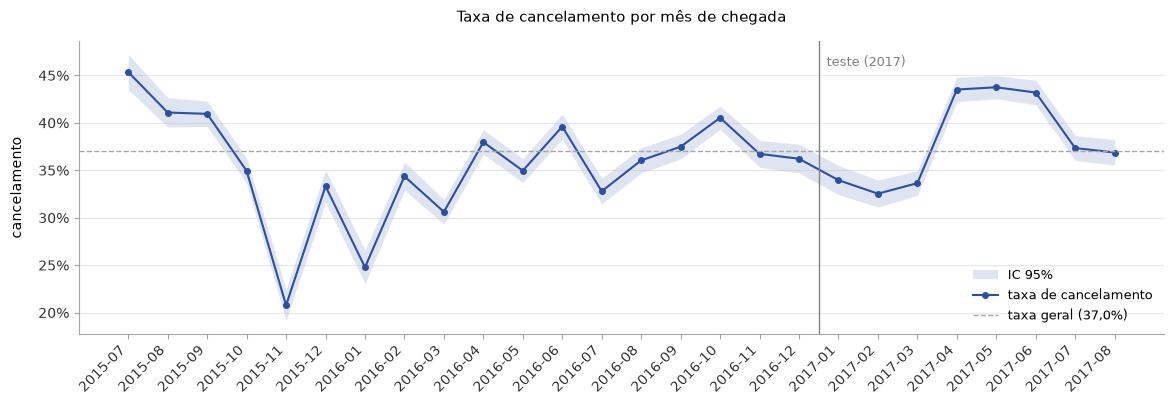

,n,taxa,ic_inf,ic_sup
mes_chegada,,,,
2015-07,2776,0.453530,0.435088,0.472101
2015-08,3889,0.410903,0.395535,0.426446
2015-09,5114,0.409464,0.396060,0.423004
2015-10,4957,0.349405,0.336253,0.362790
2015-11,2340,0.207692,0.191742,0.224601
2015-12,2920,0.333219,0.316351,0.350525
2016-01,2248,0.247776,0.230370,0.266043
2016-02,3891,0.343613,0.328852,0.358683
2016-03,4824,0.306177,0.293330,0.319334


In [6]:
# mês de chegada como período (ano-mês), para os meses saírem em ordem no tempo
hotel['mes_chegada'] = pd.to_datetime(
    hotel['arrival_date_year'].astype(str) + '-' + hotel['arrival_date_month'], format='%Y-%B'
).dt.to_period('M')

por_mes = taxa_por_nivel(hotel, 'mes_chegada')
ax = grafico_taxa_por_nivel(por_mes, taxa_geral=taxa_geral, linha=True,
                            titulo='Taxa de cancelamento por mês de chegada')
inicio_teste = list(por_mes.index).index(pd.Period('2017-01', 'M'))
ax.axvline(inicio_teste - 0.5, color='gray', linewidth=1)
ax.text(inicio_teste - 0.3, ax.get_ylim()[1] * 0.97, 'teste (2017)', fontsize=9, va='top', color='gray')
plt.show()

por_mes[['n', 'taxa', 'ic_inf', 'ic_sup']]


In [7]:
periodos = ['treino: 2015–2016', 'teste: 2017 (jan–ago)']
hotel['periodo'] = pd.Categorical(
    np.where(hotel['arrival_date_year'] == 2017, periodos[1], periodos[0]), categories=periodos
)
display(taxa_por_nivel(hotel, 'periodo'))

# os mesmos meses (janeiro a agosto) em 2016 e 2017, para separar a alta do efeito da época do ano
jan_a_ago = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August']
mesmos_meses = hotel[hotel['arrival_date_month'].isin(jan_a_ago) & hotel['arrival_date_year'].isin([2016, 2017])]
taxa_por_nivel(mesmos_meses, 'arrival_date_year')

,n,pct_base,eventos,taxa,ic_inf,ic_sup,logito
periodo,,,,,,,
treino: 2015–2016,78703,0.659209,28479,0.361854,0.358504,0.365218,-0.567318
teste: 2017 (jan–ago),40687,0.340791,15745,0.386979,0.382257,0.391722,-0.460019


,n,pct_base,eventos,taxa,ic_inf,ic_sup,logito
arrival_date_year,,,,,,,
2016,36796,0.474891,12767,0.346967,0.342120,0.351846,-0.632379
2017,40687,0.525109,15745,0.386979,0.382257,0.391722,-0.460019


**Leitura.**

- **A taxa oscila bastante de um mês para outro:** 45,4% em julho de 2015 (o primeiro mês da base), 20,8% em novembro de 2015 e perto de 44% de abril a junho de 2017. Com milhares de reservas por mês, os intervalos de confiança têm cerca de 1 ponto para cada lado: as oscilações não são acaso.
- **2017 cancela mais que o período de treino:** 38,7% contra 36,2%. Comparando os mesmos meses (janeiro a agosto), 2016 teve 34,7% e 2017, 38,7%: a alta de 4 pontos não é só efeito da época do ano.
- **O que isso muda:**
  - para **ordenar** as reservas (em quais agir primeiro), a alta geral atrapalha pouco: o que importa é o modelo colocar as reservas certas no topo;
  - para **estimar** quantos cancelamentos esperar (overbooking), as probabilidades aprendidas em 2015–2016 tendem a sair baixas para 2017. A calibração no teste precisa ser conferida;
  - no anexo técnico, a mudança entra como limitação.
- **A conferir na seção 5:** se a alta muda de tamanho dentro do escopo do modelo.

## 4. Qualidade dos dados

**Perguntas:** onde há vazios, e eles são erro ou "não se aplica"? Há linhas repetidas? Há valores impossíveis ou suspeitos?

Aqui a base inteira é usada: são problemas do próprio dado, e a limpeza decidida vale igual para treino e teste.

### 4.1 Vazios

In [8]:
display(resumo_colunas(hotel).query('missing > 0')[['missing', 'pct_missing']])

# agent e company vazios: falta de dado ou reserva sem agência / sem empresa pagando?
hotel.groupby('market_segment').agg(
    reservas=('is_canceled', 'size'),
    pct_sem_agent=('agent', lambda s: s.isna().mean()),
    pct_sem_company=('company', lambda s: s.isna().mean()),
).sort_values('reservas', ascending=False)

,missing,pct_missing
children,4,0.000034
country,488,0.004087
agent,16340,0.136862
company,112593,0.943069


,reservas,pct_sem_agent,pct_sem_company
market_segment,,,
Online TA,56477,0.006162,0.998300
Offline TA/TO,24219,0.016062,0.995623
Groups,19811,0.209379,0.929786
Direct,12606,0.476519,0.983500
Corporate,5295,0.867611,0.155619
Complementary,743,0.861373,0.578735
Aviation,237,0.894515,0.105485
Undefined,2,1.000000,1.000000


In [9]:
# as 4 reservas sem children: dá para preencher com 0 ou são cadastros incompletos?
hotel.loc[hotel['children'].isna(),
          ['hotel', 'adults', 'children', 'babies', 'market_segment', 'distribution_channel', 'is_canceled']]

,hotel,adults,children,babies,market_segment,distribution_channel,is_canceled
40600,City Hotel,2,NaN,0,Undefined,Undefined,1
40667,City Hotel,2,NaN,0,Direct,Undefined,1
40679,City Hotel,3,NaN,0,Undefined,Undefined,1
41160,City Hotel,2,NaN,0,Online TA,Undefined,1


**Leitura.**

- **Só 4 colunas têm vazios, e a maioria significa "não se aplica", não falta de dado:**
  - `agent` (16.340, 13,7%): quase não falta nas reservas por agência (0,6% na agência online e 1,6% na operadora tradicional) e falta em boa parte das reservas diretas (48%), corporativas (87%), de tripulação (89%) e de cortesia (86%). Vazio quer dizer **"sem agência"**;
  - `company` (112.593, 94,3%): só é preenchido quando uma empresa paga a reserva, o que acontece sobretudo nos segmentos corporativo (84% preenchido) e de tripulação de companhias aéreas (89%). Vazio quer dizer **"não é pago por empresa"**;
  - `country` (488): falta de dado de fato. Pesa pouco, e a variável é suspeita de vazamento (seção 5);
  - `children` (4): quatro reservas do hotel urbano, todas canceladas. Têm adultos e nenhum bebê, mas o cadastro está incompleto em outros campos também: as quatro têm `distribution_channel = Undefined` (4 das 5 reservas com canal indefinido) e duas têm `market_segment = Undefined` (as 2 únicas da base). Proposta: **remover**, como cadastros incompletos.
- **Consequência:** se `agent` ou `company` entrarem no modelo, o vazio vira uma categoria própria, e não uma linha descartada. Pelo dicionário, as duas tendem a sair (códigos sem significado para o público e coluna quase toda vazia).

### 4.2 Linhas repetidas

In [10]:
copia = hotel.duplicated()                  # repete uma linha que já apareceu antes
tem_gemea = hotel.duplicated(keep=False)    # tem pelo menos uma linha idêntica na base
print('Cópias a mais:', copia.sum(), f'({copia.mean():.1%} da base)')
print('Linhas com pelo menos uma gêmea:', tem_gemea.sum())

display(taxa_por_nivel(hotel.assign(tem_gemea=tem_gemea), 'tem_gemea'))
(hotel.assign(tem_gemea=tem_gemea)
      .groupby('market_segment')['tem_gemea'].agg(reservas='size', pct_com_gemea='mean')
      .sort_values('reservas', ascending=False))

Cópias a mais: 31994 (26.8% da base)
Linhas com pelo menos uma gêmea: 40165


,n,pct_base,eventos,taxa,ic_inf,ic_sup,logito
tem_gemea,,,,,,,
False,79225,0.663582,20773,0.262203,0.259151,0.265277,-1.034536
True,40165,0.336418,23451,0.583867,0.579038,0.588679,0.338658


,reservas,pct_com_gemea
market_segment,,
Online TA,56477,0.146414
Offline TA/TO,24219,0.504150
Groups,19811,0.843622
Direct,12606,0.111455
Corporate,5295,0.278376
Complementary,743,0.100942
Aviation,237,0.080169
Undefined,2,0.000000


**Leitura.**

- **31.994 linhas são cópia idêntica de outra (26,8% da base)**, e 40.165 têm pelo menos uma gêmea.
- **As cópias não são aleatórias:** 84% das reservas de grupo e 50% das de operadora tradicional têm gêmea, contra 15% na agência online. E as linhas com gêmea cancelam muito mais: 58,4%, contra 26,2%.

**Erro ou vários quartos de uma mesma reserva?** A base não tem número de reserva, então não dá para provar. Dá para juntar evidências: se forem quartos de uma mesma reserva, as cópias devem formar conjuntos de tamanho plausível e se concentrar onde se reserva em bloco (grupos e operadoras).

In [11]:
# cada conjunto = linhas idênticas em todas as colunas
conjuntos = (hotel.groupby(list(hotel.columns), dropna=False).size()
                  .rename('linhas').reset_index())
conjuntos = conjuntos[conjuntos['linhas'] > 1]
print('Conjuntos de linhas idênticas:', len(conjuntos))

tamanho = pd.cut(conjuntos['linhas'], [1, 2, 5, 10, 20, 50, np.inf],
                 labels=['2', '3 a 5', '6 a 10', '11 a 20', '21 a 50', 'mais de 50'])
display(tamanho.value_counts().sort_index().to_frame('conjuntos'))

display(conjuntos.groupby('market_segment')['linhas']
                 .agg(conjuntos='size', mediana='median', maximo='max')
                 .sort_values('conjuntos', ascending=False))

conjuntos.nlargest(3, 'linhas')[['hotel', 'linhas', 'market_segment', 'lead_time', 'arrival_date_year',
                                 'arrival_date_month', 'arrival_date_day_of_month', 'adr', 'is_canceled']]

Conjuntos de linhas idênticas: 8171


,conjuntos
linhas,
2,5034
3 a 5,1741
6 a 10,605
11 a 20,468
21 a 50,274
mais de 50,49


,conjuntos,mediana,maximo
market_segment,,,
Online TA,3410,2.0,15
Offline TA/TO,1880,2.0,109
Groups,1844,4.0,180
Direct,603,2.0,11
Corporate,391,2.0,99
Complementary,34,2.0,4
Aviation,9,2.0,3


,hotel,linhas,market_segment,lead_time,arrival_date_year,arrival_date_month,arrival_date_day_of_month,adr,is_canceled
52542,City Hotel,180,Groups,277,2016,November,7,100.0,1
44843,City Hotel,150,Groups,68,2016,February,17,75.0,1
50863,City Hotel,109,Offline TA/TO,188,2016,June,15,130.0,1


In [12]:
# na agência online, as linhas com gêmea parecem registros "vazios" ou se comportam diferente?
online = hotel[hotel['market_segment'] == 'Online TA'].assign(tem_gemea=tem_gemea)
online.groupby('tem_gemea').agg(
    reservas=('is_canceled', 'size'),
    taxa=('is_canceled', 'mean'),
    pct_sem_pedido_especial=('total_of_special_requests', lambda s: (s == 0).mean()),
    antecedencia_mediana=('lead_time', 'median'),
)

,reservas,taxa,pct_sem_pedido_especial,antecedencia_mediana
tem_gemea,,,,
False,48208,0.345378,0.359442,53.0
True,8269,0.494498,0.411295,97.0


**Leitura.**

- **São 8.171 conjuntos de linhas idênticas.** Mais da metade (5.034) são pares, e só 49 têm mais de 50 linhas.
- **Em grupos e operadoras, o padrão combina com blocos de quartos.** Os conjuntos de grupo têm mediana de 4 linhas. Os três maiores (180, 150 e 109 linhas) são de grupo ou de operadora, no hotel urbano, cada um com a mesma data de chegada em 2016, e foram todos cancelados: o perfil de um bloco reservado com antecedência e devolvido.
- **Na agência online, a explicação é menos clara.** Os conjuntos têm mediana de 2 linhas e chegam a 15. Um par pode ser um casal ou uma família reservando dois quartos; 15 reservas online idênticas (mesmo dia, mesmo preço, mesma antecedência) são difíceis de explicar como pessoas diferentes e podem ser registro duplicado.
- **As linhas com gêmea da agência online não parecem registros "vazios":** a parcela sem pedido especial é parecida com a das outras (41,1% contra 35,9%). Mas elas se comportam diferente: cancelam mais (49,4% contra 34,5%) e são feitas com mais antecedência (mediana de 97 dias contra 53). Parte da diferença no cancelamento pode vir da própria antecedência.
- **Conclusão:** sem número de reserva, não é possível confirmar. A explicação mais provável é a de vários quartos de uma mesma reserva, sobretudo em grupos e operadoras; na agência online, parte pode ser registro duplicado.
- **Consequências:**
  - remover as cópias apagaria quartos que provavelmente existem. A proposta é **manter** e, no modelo, rodar uma versão sem elas: se os fatores principais e a recomendação não mudarem, a dúvida não afeta a decisão;
  - como as cópias são idênticas em tudo, inclusive na data de chegada, gêmeas sempre caem do mesmo lado da divisão treino/teste. A divisão por ano não "vaza" um grupo para o teste;
  - quartos de uma mesma reserva não são independentes, o que deixa os intervalos de confiança do modelo otimistas. Entra como limitação no anexo.

### 4.3 Valores estranhos

In [13]:
hospedes = hotel['adults'] + hotel['children'].fillna(0) + hotel['babies']
noites = hotel['stays_in_weekend_nights'] + hotel['stays_in_week_nights']

casos = {
    'sem hóspede': hospedes == 0,
    'só criança ou bebê, sem adulto': (hotel['adults'] == 0) & (hospedes > 0),
    'zero noites': noites == 0,
    'diária negativa': hotel['adr'] < 0,
    'diária zero': hotel['adr'] == 0,
    'diária acima de 1.000': hotel['adr'] > 1000,
    'antecedência acima de 1 ano': hotel['lead_time'] > 365,
    'meal = Undefined': hotel['meal'] == 'Undefined',
    'market_segment = Undefined': hotel['market_segment'] == 'Undefined',
    'distribution_channel = Undefined': hotel['distribution_channel'] == 'Undefined',
}
contar_casos(hotel, casos)

,n,pct_base,taxa
sem hóspede,180,0.001508,0.138889
"só criança ou bebê, sem adulto",223,0.001868,0.376682
zero noites,715,0.005989,0.048951
diária negativa,1,0.000008,0.000000
diária zero,1959,0.016408,0.108729
diária acima de 1.000,1,0.000008,1.000000
antecedência acima de 1 ano,3148,0.026367,0.676620
meal = Undefined,1169,0.009791,0.244654
market_segment = Undefined,2,0.000017,1.000000
distribution_channel = Undefined,5,0.000042,0.800000


In [14]:
print('Maiores diárias:', hotel['adr'].nlargest(3).tolist(), '| percentil 99:', hotel['adr'].quantile(0.99))
print('Diária negativa:', hotel.loc[hotel['adr'] < 0, 'adr'].tolist())

print('\nDiária zero, por segmento:')
display(hotel.loc[hotel['adr'] == 0, 'market_segment'].value_counts().to_frame('reservas'))

print('Regime de refeição:')
taxa_por_nivel(hotel, 'meal')

Maiores diárias: [5400.0, 510.0, 508.0] | percentil 99: 252.0
Diária negativa: [-6.38]

Diária zero, por segmento:


,reservas
market_segment,
Complementary,680
Online TA,367
Offline TA/TO,332
Groups,252
Direct,240
Corporate,82
Aviation,6


Regime de refeição:


,n,pct_base,eventos,taxa,ic_inf,ic_sup,logito
meal,,,,,,,
BB,92310,0.773180,34510,0.373849,0.370733,0.376975,-0.515734
FB,798,0.006684,478,0.598997,0.564597,0.632449,0.400774
HB,14463,0.121141,4984,0.344603,0.336900,0.352389,-0.642798
SC,10650,0.089203,3966,0.372394,0.363260,0.381620,-0.521907
Undefined,1169,0.009791,286,0.244654,0.220873,0.270106,-1.126153


**Leitura.**

- **Impossíveis:**
  - **180 reservas sem nenhum hóspede.** Erro de cadastro. Proposta: **remover**;
  - **uma diária negativa (−6,38) e uma de 5.400**, quando a segunda maior é 510 e o percentil 99 é 252. Erros de digitação. Proposta: **remover as duas**.
- **Suspeitos, mas possíveis:**
  - **223 reservas só com crianças ou bebês, sem adulto.** Pouco provável na prática, mas cancelam como o resto (37,7%) e são poucas. Proposta: manter;
  - **715 reservas com zero noites** (*day use*, uso do quarto durante o dia?). Quase não cancelam (4,9%). Proposta: manter, juntando com as de uma noite quando o total de noites for usado;
  - **1.959 reservas com diária zero.** 680 são cortesia (Complementary), o que faz sentido; as outras se espalham pelos segmentos (pacotes? erro?). Cancelam pouco (10,9%). Proposta: manter;
  - **3.148 reservas feitas com mais de um ano de antecedência**, com 67,7% de cancelamento. Não é erro: combina com blocos de quartos reservados por operadoras. A seção 5 olha essas reservas de novo.
- **Vazios disfarçados (`Undefined`):**
  - `meal = Undefined` (1.169): a documentação diz que é o mesmo que SC (sem refeição), mas os dois não se comportam igual (24,5% contra 37,2% de cancelamento). Proposta: **manter separado**, como "não informado";
  - `market_segment = Undefined` (2) e `distribution_channel = Undefined` (5): quase todas são as reservas sem `children` (seção 4.1), que já saem como cadastros incompletos. Sobra uma reserva com canal indefinido. Proposta: juntar em "Outros" se a variável entrar.

### Propostas de limpeza (para o grupo decidir)

| Situação | Reservas | Proposta |
|---|---|---|
| `children` vazio (cadastro incompleto) | 4 | remover |
| `agent` / `company` vazios | 16.340 / 112.593 | categoria "sem agência" / "sem empresa", se a variável entrar |
| Linhas idênticas | 31.994 cópias | manter; conferir o modelo sem elas |
| Sem hóspede | 180 | remover |
| Diária negativa ou de 5.400 | 2 | remover |
| Zero noites | 715 | manter; juntar com 1 noite no total de noites |
| `meal = Undefined` | 1.169 | manter separado ("não informado") |
| `Undefined` no segmento e no canal | 2 e 5 (quase todas entre as 4 acima) | as que sobram vão para "Outros" |

## 5. Vazamento e escopo

**Perguntas:** quais colunas trazem informação de depois da reserva? E em quais reservas o modelo vai ser usado?

O dicionário (seção 2) marcou quatro colunas como **só no fim** e duas como **?**. Aqui os dados confirmam ou derrubam cada suspeita. A base ainda é a inteira.

### 5.1 Vazamento

In [15]:
# data do último status em relação à chegada: antes, no dia ou depois?
chegada = pd.to_datetime(
    hotel['arrival_date_year'].astype(str) + '-' + hotel['arrival_date_month'] + '-'
    + hotel['arrival_date_day_of_month'].astype(str), format='%Y-%B-%d')
dias_status = (pd.to_datetime(hotel['reservation_status_date']) - chegada).dt.days

momento = pd.cut(dias_status, [-np.inf, -1, 0, np.inf], labels=['antes da chegada', 'no dia', 'depois da chegada']).rename('data do status')
display(pd.crosstab(hotel['reservation_status'], momento, normalize='index').round(3))

# para quem veio, o status muda no check-out: chegada + noites
check_out = hotel['reservation_status'] == 'Check-Out'
print('Check-Out com data = chegada + noites:', f"{(dias_status[check_out] == noites[check_out]).mean():.2%}")

data do status,antes da chegada,no dia,depois da chegada
reservation_status,,,
Canceled,0.980,0.020,0.000
Check-Out,0.000,0.009,0.991
No-Show,0.001,0.999,0.000


Check-Out com data = chegada + noites: 99.96%


In [16]:
# colunas preenchidas ou alteradas depois da reserva: o y já aparece nelas?
casos = {
    'quarto entregue = reservado': hotel['assigned_room_type'] == hotel['reserved_room_type'],
    'quarto entregue diferente do reservado': hotel['assigned_room_type'] != hotel['reserved_room_type'],
    'sem alteração na reserva': hotel['booking_changes'] == 0,
    'com alteração na reserva': hotel['booking_changes'] > 0,
    'sem vaga de garagem': hotel['required_car_parking_spaces'] == 0,
    'com vaga de garagem': hotel['required_car_parking_spaces'] > 0,
}
contar_casos(hotel, casos)

,n,pct_base,taxa
quarto entregue = reservado,104473,0.875057,0.415629
quarto entregue diferente do reservado,14917,0.124943,0.053764
sem alteração na reserva,101314,0.848597,0.408542
com alteração na reserva,18076,0.151403,0.156727
sem vaga de garagem,111974,0.937884,0.394949
com vaga de garagem,7416,0.062116,0.000000


In [17]:
# país: Portugal cancela mais em todos os segmentos, ou só onde o país pode ter sido preenchido no check-in?
hotel['pais'] = np.select([hotel['country'].isna(), hotel['country'] == 'PRT'], ['vazio', 'Portugal'], 'outro')
display(taxa_por_nivel(hotel, 'pais'))

segmentos = ['Online TA', 'Offline TA/TO', 'Groups', 'Direct', 'Corporate']
(hotel[hotel['market_segment'].isin(segmentos)]
      .pivot_table(index='market_segment', columns='pais', values='is_canceled', aggfunc='mean')
      .loc[segmentos, ['Portugal', 'outro']].round(3))

,n,pct_base,eventos,taxa,ic_inf,ic_sup,logito
pais,,,,,,,
Portugal,48590,0.406986,27519,0.566351,0.561940,0.570752,0.266973
outro,70312,0.588927,16638,0.236631,0.233504,0.239787,-1.171219
vazio,488,0.004087,67,0.137295,0.109581,0.170675,-1.831692


pais,Portugal,outro
market_segment,,
Online TA,0.453,0.345
Offline TA/TO,0.678,0.013
Groups,0.840,0.072
Direct,0.206,0.108
Corporate,0.233,0.020


**Leitura.**

- **`reservation_status_date` é a data do desfecho.** 98,0% das canceladas têm a data antes da chegada (o dia do cancelamento), quase todos os no-shows têm a data no próprio dia e 99,1% de quem veio tem a data depois da chegada: em 99,96% dos check-outs, é a chegada mais as noites. Junto com `reservation_status` (seção 3), as duas descrevem o `y`. **Saem.**
- **Três colunas carregam o desfecho:**
  - `assigned_room_type`: quando o quarto entregue é diferente do reservado, só 5,4% cancelam, contra 41,6%. O quarto é definido no check-in, e quem cancela nunca recebe um. **Sai;**
  - `booking_changes`: com alteração, 15,7% cancelam, contra 40,9% sem. Quem fica mais tempo com a reserva ativa tem mais chance de alterá-la, e no momento da reserva a contagem é sempre zero. **Sai;**
  - `required_car_parking_spaces`: nenhuma das 7.416 reservas com vaga foi cancelada. Uma taxa de exatamente 0% em milhares de reservas indica que a vaga é registrada na chegada. **Sai.**
- **`country` é suspeito.** Portugal cancela 56,6%, contra 23,7% dos outros países. Na agência online, a diferença é moderada (45,3% contra 34,5%). Em grupos e operadoras, é extrema: 84,0% contra 7,2% e 67,8% contra 1,3%. Uma explicação provável é o país ser preenchido no check-in, com Portugal como valor padrão de quem nunca chegou. Não dá para provar, mas o risco não compensa. **Sai.**
- **`stays_in_*_nights` e `total_of_special_requests` podem mudar até a chegada.** Não carregam o desfecho como as colunas acima, mas a base guarda o valor final. Ficam como candidatas e voltam na bivariada.

| Variável | Por que sai |
| --- | --- |
| `reservation_status` | É o próprio `y` (Canceled e No-Show = 1) |
| `reservation_status_date` | Data do cancelamento ou do check-out |
| `assigned_room_type` | Definido no check-in |
| `booking_changes` | Acumula até o desfecho; na reserva, é zero |
| `required_car_parking_spaces` | Nenhuma reserva com vaga cancelou: registrada na chegada |
| `country` | Suspeita de preenchimento no check-in |

### 5.2 Escopo

In [18]:
# deposit_type: entra como variável ou define o escopo?
display(taxa_por_nivel(hotel, 'deposit_type'))

hotel.assign(tem_gemea=tem_gemea).groupby('deposit_type').agg(
    reservas=('is_canceled', 'size'),
    antecedencia_mediana=('lead_time', 'median'),
    pct_grupo_ou_operadora=('market_segment', lambda s: s.isin(['Groups', 'Offline TA/TO']).mean()),
    pct_portugal=('pais', lambda s: (s == 'Portugal').mean()),
    pct_com_gemea=('tem_gemea', 'mean'),
)

,n,pct_base,eventos,taxa,ic_inf,ic_sup,logito
deposit_type,,,,,,,
No Deposit,104641,0.876464,29694,0.283770,0.281047,0.286510,-0.925826
Non Refund,14587,0.122179,14494,0.993624,0.992197,0.994792,5.043563
Refundable,162,0.001357,36,0.222222,0.165057,0.292256,-1.242930


,reservas,antecedencia_mediana,pct_grupo_ou_operadora,pct_portugal,pct_com_gemea
deposit_type,,,,,
No Deposit,104641,56.0,0.284000,0.328418,0.246299
Non Refund,14587,183.0,0.971961,0.971824,0.981422
Refundable,162,169.0,0.827160,0.296296,0.469136


In [19]:
# dentro do escopo proposto (sem depósito): a alta de 2017 continua?
escopo = hotel[hotel['deposit_type'] == 'No Deposit']
display(taxa_por_nivel(escopo, 'periodo'))
taxa_por_nivel(escopo[escopo['arrival_date_month'].isin(jan_a_ago) & escopo['arrival_date_year'].isin([2016, 2017])],
               'arrival_date_year')

,n,pct_base,eventos,taxa,ic_inf,ic_sup,logito
periodo,,,,,,,
treino: 2015–2016,68107,0.650863,18093,0.265656,0.262352,0.268986,-1.016760
teste: 2017 (jan–ago),36534,0.349137,11601,0.317540,0.312786,0.322332,-0.765078


,n,pct_base,eventos,taxa,ic_inf,ic_sup,logito
arrival_date_year,,,,,,,
2016,32317,0.469376,8465,0.261936,0.257171,0.266758,-1.035890
2017,36534,0.530624,11601,0.317540,0.312786,0.322332,-0.765078


**Leitura.**

- **Non Refund cancela 99,4%**, o contrário do esperado: quem pagou sem reembolso deveria vir. E o perfil é outro: antecedência mediana de 183 dias (contra 56 sem depósito), 97,2% de grupos ou operadoras, 97,2% de Portugal e 98,1% de linhas com gêmea. São os blocos de quartos da seção 4.2, quase todos devolvidos.
- **Se `deposit_type` entrasse como variável,** o modelo aprenderia que "pedir depósito leva a cancelar", o oposto da ação em discussão. O efeito vem do tipo de cliente, não do depósito.
- **A decisão só se aplica a quem não deu garantia.** Pedir depósito ou ligar para confirmar não faz sentido para quem já pagou. As 162 Refundable são poucas para estimar qualquer efeito.
- **Proposta: o modelo usa só as reservas sem depósito** (104.641, 28,4% de cancelamento). A frase da apresentação passa a ser "entre as reservas sem garantia de pagamento, 28% são canceladas".
- **A alta de 2017 cresce no escopo.** Treino 26,6%, teste 31,8%. Nos mesmos meses (janeiro a agosto), de 26,2% em 2016 para 31,8% em 2017: 5,6 pontos, contra 4 na base inteira. A calibração no teste fica ainda mais importante.
- **Consequência para o resto do notebook:** as seções 6 e 7 usam o escopo, e as decisões da bivariada saem só do treino (2015 e 2016).